# Unemployment Analysis with Python

## 1. Project Introduction

### Project Overview

Unemployment is an important economic indicator that reflects the proportion of the labor force that is currently without employment but actively seeking work.

This project aims to analyze unemployment trends in India using Python and data analysis techniques.

The analysis focuses on understanding unemployment patterns across different regions and time periods, exploring changes in unemployment rates, and investigating the potential impact of the COVID-19 pandemic.

### Project Objectives

The main objectives of this project are:

- Explore and understand the available unemployment datasets.
- Clean and prepare the data for reliable analysis.
- Analyze unemployment rates across different regions and periods.
- Visualize unemployment trends using appropriate statistical charts.
- Investigate changes in unemployment during the COVID-19 period.
- Identify meaningful patterns and provide insights that may support economic and social policy discussions.

### Project Methodology

The project follows a structured data analysis workflow:

1. Data loading and initial inspection.
2. Data cleaning and preprocessing.
3. Exploratory Data Analysis (EDA).
4. Statistical analysis and data visualization.
5. COVID-19 impact analysis.
6. Identification of trends and potential seasonal patterns.
7. Interpretation of findings and policy insights.

### Tools and Technologies

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Jupyter Notebook

### Dataset Description

This project uses two CSV datasets provided for the CodeAlpha Unemployment Analysis task. Their structure, variables, time coverage, and data quality will be examined before defining the detailed analysis.

## 2. Importing Libraries

In this section, we import the Python libraries required to perform data loading, cleaning, statistical analysis, and visualization.

The following libraries will be used:

- **Pandas:** for loading, manipulating, and analyzing tabular data.
- **NumPy:** for numerical operations and calculations.
- **Matplotlib:** for creating data visualizations.
- **Seaborn:** for producing statistical charts and exploring relationships between variables.
- **Warnings:** to manage unnecessary warning messages during the analysis.

In [2]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Warning management
import warnings
warnings.filterwarnings("ignore")

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


## 3. Loading the Dataset

In this section, we load the two CSV files provided with the dataset.

Before starting the analysis, we need to examine both datasets independently to understand their structure, dimensions, column names, and data types.

This initial inspection will help us determine whether the datasets can be analyzed separately or combined for further analysis.

In [3]:
# Load the two datasets
df_india = pd.read_csv("../data/Unemployment in India.csv")
df_upto_2020 = pd.read_csv("../data/Unemployment_Rate_upto_11_2020.csv")

print("Dataset 1: Unemployment in India")
print("Shape:", df_india.shape)
display(df_india.head())

print("\nDataset 2: Unemployment Rate up to November 2020")
print("Shape:", df_upto_2020.shape)
display(df_upto_2020.head())

Dataset 1: Unemployment in India
Shape: (768, 7)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural



Dataset 2: Unemployment Rate up to November 2020
Shape: (267, 9)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
0,Andhra Pradesh,31-01-2020,M,5.48,16635535,41.02,South,15.9129,79.74
1,Andhra Pradesh,29-02-2020,M,5.83,16545652,40.90,South,15.9129,79.74
2,Andhra Pradesh,31-03-2020,M,5.79,15881197,39.18,South,15.9129,79.74
3,Andhra Pradesh,30-04-2020,M,20.51,11336911,33.10,South,15.9129,79.74
4,Andhra Pradesh,31-05-2020,M,17.43,12988845,36.46,South,15.9129,79.74


## 4. Initial Data Inspection

In this section, we examine the datasets in more detail to understand their structure and data quality.

We will:
- Inspect column names and data types.
- Check the number of missing values.
- Identify duplicated records.
- Examine the date ranges covered by each dataset.
- Explore the unique values of important categorical variables.

These checks will help us identify potential data quality issues before starting the cleaning process.

In [6]:
# Display exact column names
print("Dataset 1:")
for col in df_india.columns:
    print(repr(col))

print("\nDataset 2:")
for col in df_upto_2020.columns:
    print(repr(col))

Dataset 1:
'Region'
' Date'
' Frequency'
' Estimated Unemployment Rate (%)'
' Estimated Employed'
' Estimated Labour Participation Rate (%)'
'Area'

Dataset 2:
'Region'
' Date'
' Frequency'
' Estimated Unemployment Rate (%)'
' Estimated Employed'
' Estimated Labour Participation Rate (%)'
'Region.1'
'longitude'
'latitude'


In [7]:
# Clean column names in both datasets
df_india.columns = df_india.columns.str.strip()
df_upto_2020.columns = df_upto_2020.columns.str.strip()

# Verify
print("Dataset 1:", df_india.columns.tolist())
print("Dataset 2:", df_upto_2020.columns.tolist())

Dataset 1: ['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area']
Dataset 2: ['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Region.1', 'longitude', 'latitude']


In [8]:
# Dataset 1
dates_1 = pd.to_datetime(
    df_india["Date"], dayfirst=True, errors="coerce"
)

print("Dataset 1 date range:")
print(dates_1.min(), "to", dates_1.max())


# Dataset 2
dates_2 = pd.to_datetime(
    df_upto_2020["Date"], dayfirst=True, errors="coerce"
)

print("\nDataset 2 date range:")
print(dates_2.min(), "to", dates_2.max())

Dataset 1 date range:
2019-05-31 00:00:00 to 2020-06-30 00:00:00

Dataset 2 date range:
2020-01-31 00:00:00 to 2020-10-31 00:00:00


In [9]:
# Inspect Dataset 1
print("=" * 60)
print("DATASET 1: UNEMPLOYMENT IN INDIA")
print("=" * 60)

print("\nColumn names:")
print(df_india.columns.tolist())

print("\nData types and non-null values:")
df_india.info()

print("\nMissing values:")
display(df_india.isnull().sum().to_frame("Missing Values"))

print("\nNumber of duplicated rows:")
print(df_india.duplicated().sum())

print("\nDate range:")
dates_1 = pd.to_datetime(df_india["Date"], dayfirst=True, errors="coerce")
print("Start:", dates_1.min())
print("End:", dates_1.max())

print("\nUnique Regions:", df_india["Region"].nunique())
print("Unique Areas:", df_india["Area"].unique())


# Inspect Dataset 2
print("\n" + "=" * 60)
print("DATASET 2: UNEMPLOYMENT RATE UP TO NOVEMBER 2020")
print("=" * 60)

print("\nColumn names:")
print(df_upto_2020.columns.tolist())

print("\nData types and non-null values:")
df_upto_2020.info()

print("\nMissing values:")
display(df_upto_2020.isnull().sum().to_frame("Missing Values"))

print("\nNumber of duplicated rows:")
print(df_upto_2020.duplicated().sum())

print("\nDate range:")
dates_2 = pd.to_datetime(df_upto_2020["Date"], dayfirst=True, errors="coerce")
print("Start:", dates_2.min())
print("End:", dates_2.max())

print("\nUnique Regions:", df_upto_2020["Region"].nunique())
print("Unique Region Categories:", df_upto_2020["Region.1"].unique())

DATASET 1: UNEMPLOYMENT IN INDIA

Column names:
['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area']

Data types and non-null values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   Region                                   740 non-null    object 
 1   Date                                     740 non-null    object 
 2   Frequency                                740 non-null    object 
 3   Estimated Unemployment Rate (%)          740 non-null    float64
 4   Estimated Employed                       740 non-null    float64
 5   Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                     740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 4

,Missing Values
Region,28
Date,28
Frequency,28
Estimated Unemployment Rate (%),28
Estimated Employed,28
Estimated Labour Participation Rate (%),28
Area,28



Number of duplicated rows:
27

Date range:
Start: 2019-05-31 00:00:00
End: 2020-06-30 00:00:00

Unique Regions: 28
Unique Areas: ['Rural' nan 'Urban']

DATASET 2: UNEMPLOYMENT RATE UP TO NOVEMBER 2020

Column names:
['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Region.1', 'longitude', 'latitude']

Data types and non-null values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 9 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   Region                                   267 non-null    object 
 1   Date                                     267 non-null    object 
 2   Frequency                                267 non-null    object 
 3   Estimated Unemployment Rate (%)          267 non-null    float64
 4   Estimated Employed                       267 non-nul

,Missing Values
Region,0
Date,0
Frequency,0
Estimated Unemployment Rate (%),0
Estimated Employed,0
Estimated Labour Participation Rate (%),0
Region.1,0
longitude,0
latitude,0



Number of duplicated rows:
0

Date range:
Start: 2020-01-31 00:00:00
End: 2020-10-31 00:00:00

Unique Regions: 27
Unique Region Categories: ['South' 'Northeast' 'East' 'West' 'North']


## 5. Data Cleaning

Data cleaning is an essential step before performing any analysis.

The initial inspection revealed missing values, duplicated records, and unnecessary spaces in the column names.

In this section, we will:

- Remove rows containing missing values.
- Remove duplicated records.
- Convert date columns into the appropriate datetime format.
- Ensure that numerical variables have the correct data types.
- Verify the quality of the cleaned datasets.

The two datasets will be cleaned independently to preserve their original structures.

In [10]:
# Create copies to preserve the original datasets
df_india_clean = df_india.copy()
df_upto_2020_clean = df_upto_2020.copy()

# Store the initial number of rows
initial_rows_1 = len(df_india_clean)
initial_rows_2 = len(df_upto_2020_clean)

# Remove completely empty rows
df_india_clean.dropna(how="all", inplace=True)
df_upto_2020_clean.dropna(how="all", inplace=True)

# Display cleaning results
print("DATASET 1")
print("Rows before cleaning:", initial_rows_1)
print("Rows after removing empty rows:", len(df_india_clean))
print("Rows removed:", initial_rows_1 - len(df_india_clean))
print("Remaining missing values:", df_india_clean.isnull().sum().sum())
print("Duplicated rows:", df_india_clean.duplicated().sum())

print("\nDATASET 2")
print("Rows before cleaning:", initial_rows_2)
print("Rows after removing empty rows:", len(df_upto_2020_clean))
print("Rows removed:", initial_rows_2 - len(df_upto_2020_clean))
print("Remaining missing values:", df_upto_2020_clean.isnull().sum().sum())
print("Duplicated rows:", df_upto_2020_clean.duplicated().sum()) 

DATASET 1
Rows before cleaning: 768
Rows after removing empty rows: 740
Rows removed: 28
Remaining missing values: 0
Duplicated rows: 0

DATASET 2
Rows before cleaning: 267
Rows after removing empty rows: 267
Rows removed: 0
Remaining missing values: 0
Duplicated rows: 0


### 5.2 Date Conversion

The date columns are currently stored as text values.

To perform time-based analysis, we convert them into the datetime format.

This will allow us to:
- Sort observations chronologically.
- Extract the year and month.
- Analyze unemployment trends over time.
- Compare unemployment rates before and during the COVID-19 period.

In [11]:
# Convert Date columns to datetime format
df_india_clean["Date"] = pd.to_datetime(
    df_india_clean["Date"],
    dayfirst=True,
    errors="coerce"
)

df_upto_2020_clean["Date"] = pd.to_datetime(
    df_upto_2020_clean["Date"],
    dayfirst=True,
    errors="coerce"
)

# Verify the conversion
print("DATASET 1")
print("Date data type:", df_india_clean["Date"].dtype)
print("Date range:", df_india_clean["Date"].min(), "to", df_india_clean["Date"].max())

print("\nDATASET 2")
print("Date data type:", df_upto_2020_clean["Date"].dtype)
print("Date range:", df_upto_2020_clean["Date"].min(), "to", df_upto_2020_clean["Date"].max())

# Check for invalid dates
print("\nInvalid dates in Dataset 1:", df_india_clean["Date"].isna().sum())
print("Invalid dates in Dataset 2:", df_upto_2020_clean["Date"].isna().sum())

DATASET 1
Date data type: datetime64[ns]
Date range: 2019-05-31 00:00:00 to 2020-06-30 00:00:00

DATASET 2
Date data type: datetime64[ns]
Date range: 2020-01-31 00:00:00 to 2020-10-31 00:00:00

Invalid dates in Dataset 1: 0
Invalid dates in Dataset 2: 0


### 5.3 Data Type Verification

In this step, we verify the data types of all columns in both cleaned datasets.

Numerical variables must be stored using appropriate numeric data types, while categorical variables should be handled as text.

This verification ensures that the datasets are ready for statistical calculations and visualizations.

In [12]:
# Display data types for Dataset 1
print("DATASET 1 - Data Types")
display(df_india_clean.dtypes.to_frame("Data Type"))

# Display data types for Dataset 2
print("\nDATASET 2 - Data Types")
display(df_upto_2020_clean.dtypes.to_frame("Data Type"))

# Check numerical columns
numerical_columns_1 = df_india_clean.select_dtypes(include=np.number).columns.tolist()
numerical_columns_2 = df_upto_2020_clean.select_dtypes(include=np.number).columns.tolist()

print("\nNumerical columns in Dataset 1:")
print(numerical_columns_1)

print("\nNumerical columns in Dataset 2:")
print(numerical_columns_2)

DATASET 1 - Data Types


,Data Type
Region,object
Date,datetime64[ns]
Frequency,object
Estimated Unemployment Rate (%),float64
Estimated Employed,float64
Estimated Labour Participation Rate (%),float64
Area,object



DATASET 2 - Data Types


,Data Type
Region,object
Date,datetime64[ns]
Frequency,object
Estimated Unemployment Rate (%),float64
Estimated Employed,int64
Estimated Labour Participation Rate (%),float64
Region.1,object
longitude,float64
latitude,float64



Numerical columns in Dataset 1:
['Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)']

Numerical columns in Dataset 2:
['Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'longitude', 'latitude']


### 5.4 Final Cleaning Verification

In this final step, we perform a quality check on both cleaned datasets.

We verify that:
- No missing values remain.
- No duplicated records remain.
- All dates are valid.
- The datasets retain the expected number of observations.

This final verification confirms whether the datasets are ready for exploratory data analysis.

In [13]:
# Final quality check for Dataset 1
print("=" * 50)
print("FINAL CHECK - DATASET 1")
print("=" * 50)

print("Number of rows:", len(df_india_clean))
print("Missing values:", df_india_clean.isnull().sum().sum())
print("Duplicated rows:", df_india_clean.duplicated().sum())
print("Invalid dates:", df_india_clean["Date"].isna().sum())


# Final quality check for Dataset 2
print("\n" + "=" * 50)
print("FINAL CHECK - DATASET 2")
print("=" * 50)

print("Number of rows:", len(df_upto_2020_clean))
print("Missing values:", df_upto_2020_clean.isnull().sum().sum())
print("Duplicated rows:", df_upto_2020_clean.duplicated().sum())
print("Invalid dates:", df_upto_2020_clean["Date"].isna().sum())

FINAL CHECK - DATASET 1
Number of rows: 740
Missing values: 0
Duplicated rows: 0
Invalid dates: 0

FINAL CHECK - DATASET 2
Number of rows: 267
Missing values: 0
Duplicated rows: 0
Invalid dates: 0


### Data Cleaning Summary

The data cleaning process was successfully completed for both datasets.

The first dataset contains 740 valid observations after removing 28 completely empty rows, while the second dataset retains all 267 observations.

Both datasets were checked for missing values, duplicated records, and invalid dates. No remaining data quality issues were identified.

The date columns were successfully converted into datetime format, and all numerical variables have appropriate data types.

The cleaned datasets are now ready for Exploratory Data Analysis (EDA).

## 6. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is the process of examining and understanding a dataset using statistical summaries and visualizations.

In this section, we explore the main characteristics of unemployment data to identify distributions, regional differences, and temporal patterns.

The analysis will focus on the unemployment rate, estimated employment, and labour participation rate.

### 6.1 Descriptive Statistics

Descriptive statistics provide a numerical summary of the main variables in the datasets.

In this step, we analyze the central tendency and dispersion of the economic indicators using:

- Mean: the average value.
- Median: the middle value.
- Standard deviation: the variability of the data.
- Minimum and maximum: the lowest and highest observed values.

This analysis provides an initial understanding of unemployment rates, estimated employment, and labour participation.

In [14]:
# Descriptive statistics for Dataset 1
print("DATASET 1 - Descriptive Statistics")
display(df_india_clean.describe().round(2))

# Descriptive statistics for Dataset 2
print("\nDATASET 2 - Descriptive Statistics")
display(df_upto_2020_clean.describe().round(2))

DATASET 1 - Descriptive Statistics


,Date,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740,740.00,740.00,740.00
mean,2019-12-12 18:36:58.378378496,11.79,7204460.03,42.63
min,2019-05-31 00:00:00,0.00,49420.00,13.33
25%,2019-08-31 00:00:00,4.66,1190404.50,38.06
50%,2019-11-30 00:00:00,8.35,4744178.50,41.16
75%,2020-03-31 00:00:00,15.89,11275489.50,45.50
max,2020-06-30 00:00:00,76.74,45777509.00,72.57
std,NaN,10.72,8087988.43,8.11



DATASET 2 - Descriptive Statistics


,Date,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),longitude,latitude
count,267,267.00,267.00,267.00,267.00,267.00
mean,2020-06-16 09:15:30.337078528,12.24,13962105.72,41.68,22.83,80.53
min,2020-01-31 00:00:00,0.50,117542.00,16.77,10.85,71.19
25%,2020-03-31 00:00:00,4.84,2838930.50,37.26,18.11,76.09
50%,2020-06-30 00:00:00,9.65,9732417.00,40.39,23.61,79.02
75%,2020-08-31 00:00:00,16.76,21878686.00,44.06,27.28,85.28
max,2020-10-31 00:00:00,75.85,59433759.00,69.69,33.78,92.94
std,NaN,10.80,13366318.36,7.85,6.27,5.83


### 6.2 Identifying Extreme Unemployment Rates

The descriptive statistics revealed unusually high maximum unemployment rates in both datasets.

In this section, we investigate these extreme observations to identify the regions, dates, and areas associated with the highest unemployment rates.

These values will be examined before deciding whether they represent genuine observations or potential data quality issues.

In [15]:
# Select the most relevant columns from Dataset 1
top_unemployment_1 = df_india_clean.nlargest(
    10, "Estimated Unemployment Rate (%)"
)[[
    "Region",
    "Date",
    "Estimated Unemployment Rate (%)",
    "Area"
]]

print("DATASET 1 - Top 10 Highest Unemployment Rates")
display(top_unemployment_1.reset_index(drop=True))


# Select the most relevant columns from Dataset 2
top_unemployment_2 = df_upto_2020_clean.nlargest(
    10, "Estimated Unemployment Rate (%)"
)[[
    "Region",
    "Date",
    "Estimated Unemployment Rate (%)",
    "Region.1"
]]

print("\nDATASET 2 - Top 10 Highest Unemployment Rates")
display(top_unemployment_2.reset_index(drop=True))

DATASET 1 - Top 10 Highest Unemployment Rates


,Region,Date,Estimated Unemployment Rate (%),Area
0,Puducherry,2020-04-30,76.74,Urban
1,Puducherry,2020-05-31,75.00,Urban
2,Puducherry,2020-04-30,74.51,Rural
3,Jharkhand,2020-05-31,70.17,Urban
4,Jharkhand,2020-04-30,61.48,Urban
5,Bihar,2020-04-30,58.77,Urban
6,Jharkhand,2020-05-31,55.10,Rural
7,Tamil Nadu,2020-04-30,53.19,Rural
8,Himachal Pradesh,2020-05-31,50.00,Urban
9,Bihar,2020-05-31,47.26,Rural



DATASET 2 - Top 10 Highest Unemployment Rates


,Region,Date,Estimated Unemployment Rate (%),Region.1
0,Puducherry,2020-04-30,75.85,South
1,Jharkhand,2020-05-31,59.23,East
2,Puducherry,2020-05-31,58.19,South
3,Tamil Nadu,2020-04-30,49.83,South
4,Jharkhand,2020-04-30,47.09,East
5,Bihar,2020-04-30,46.64,East
6,Bihar,2020-05-31,45.96,East
7,Haryana,2020-04-30,43.22,North
8,Delhi,2020-05-31,42.27,North
9,Tripura,2020-04-30,41.23,Northeast


### 6.3 Unemployment Rate Distribution

In this section, we analyze the distribution of unemployment rates in both datasets.

Histograms help us understand how frequently different unemployment rate values occur, while KDE curves provide a smoothed representation of the distributions.

This analysis will help identify:
- The most common unemployment rate ranges.
- The spread and variability of unemployment rates.
- Differences between the two datasets.
- Potentially skewed distributions and extreme values.

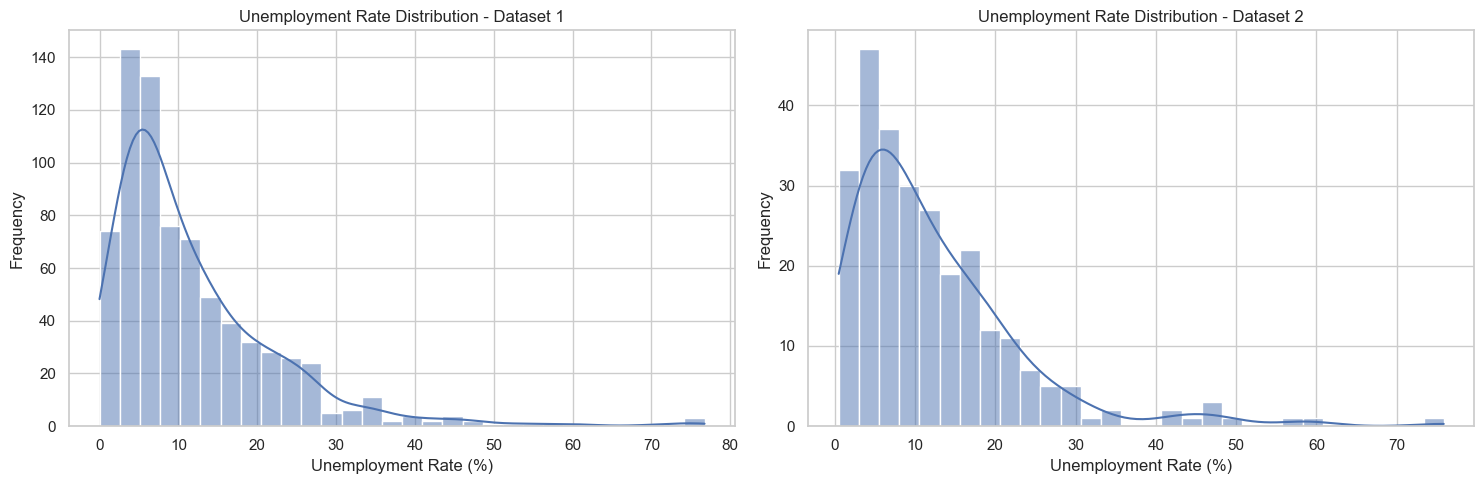

In [16]:
# Create a figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Dataset 1 distribution
sns.histplot(
    data=df_india_clean,
    x="Estimated Unemployment Rate (%)",
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Unemployment Rate Distribution - Dataset 1")
axes[0].set_xlabel("Unemployment Rate (%)")
axes[0].set_ylabel("Frequency")


# Dataset 2 distribution
sns.histplot(
    data=df_upto_2020_clean,
    x="Estimated Unemployment Rate (%)",
    bins=30,
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Unemployment Rate Distribution - Dataset 2")
axes[1].set_xlabel("Unemployment Rate (%)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

### 6.4 Unemployment Rate by Region

In this section, we analyze unemployment rates across different Indian regions.

The objective is to identify regions with the highest and lowest average unemployment rates.

A regional comparison will help highlight geographical differences in unemployment and identify areas that may require greater attention.

Average Unemployment Rate by Region:


,Average Unemployment Rate (%)
Region,
Tripura,28.35
Haryana,26.28
Jharkhand,20.58
Bihar,18.92
Himachal Pradesh,18.54
Delhi,16.50
Jammu & Kashmir,16.19
Chandigarh,15.99
Rajasthan,14.06


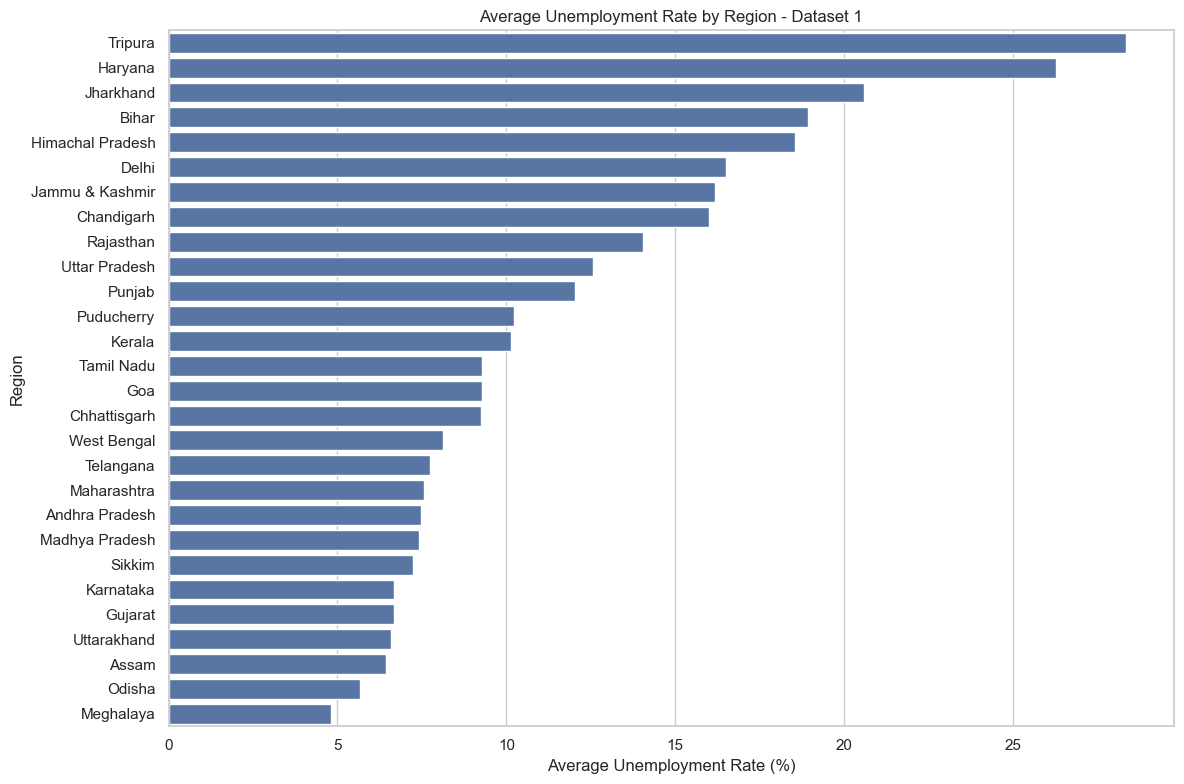

In [17]:
# Calculate average unemployment rate by region
regional_unemployment = (
    df_india_clean
    .groupby("Region")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values(ascending=False)
)

# Display regional statistics
print("Average Unemployment Rate by Region:")
display(regional_unemployment.round(2).to_frame("Average Unemployment Rate (%)"))

# Create a horizontal bar chart
plt.figure(figsize=(12, 8))

sns.barplot(
    x=regional_unemployment.values,
    y=regional_unemployment.index
)

plt.title("Average Unemployment Rate by Region - Dataset 1")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

### 6.5 Unemployment Rate by Area

In this section, we compare unemployment rates between rural and urban areas.

The objective is to determine whether unemployment levels differ between these two geographical categories.

We will calculate the average unemployment rate for each area and visualize the comparison using a bar chart.

Average Unemployment Rate by Area:


,Average Unemployment Rate (%)
Area,
Urban,13.17
Rural,10.32


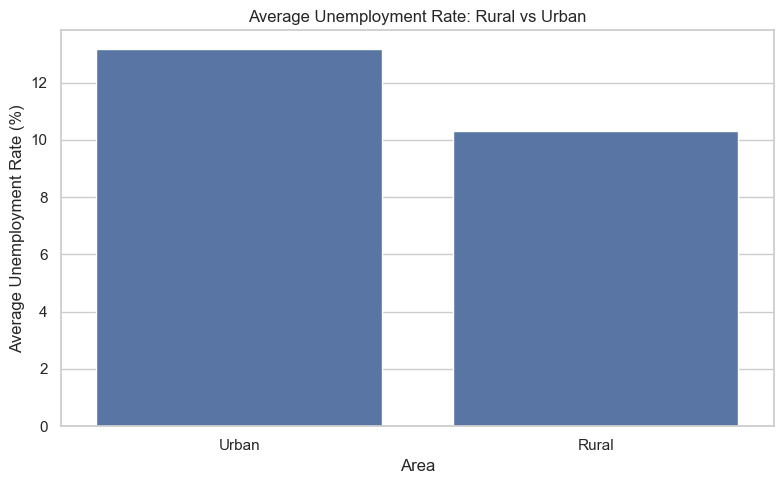

In [18]:
# Calculate average unemployment rate by area
area_unemployment = (
    df_india_clean
    .groupby("Area")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values(ascending=False)
)

# Display the results
print("Average Unemployment Rate by Area:")
display(area_unemployment.round(2).to_frame("Average Unemployment Rate (%)"))

# Create a bar chart
plt.figure(figsize=(8, 5))

sns.barplot(
    x=area_unemployment.index,
    y=area_unemployment.values
)

plt.title("Average Unemployment Rate: Rural vs Urban")
plt.xlabel("Area")
plt.ylabel("Average Unemployment Rate (%)")

plt.tight_layout()
plt.show()

**Interpretation:**

The analysis shows that urban areas have a higher average unemployment rate (13.17%) than rural areas (10.32%).

The difference is approximately 2.85 percentage points.

This suggests that unemployment patterns differ between urban and rural areas during the period covered by the dataset.

However, these results are descriptive and do not establish the underlying causes of the observed differences.

### 6.6 Labour Market Indicators Analysis

In this section, we examine the relationships between the main labour market indicators.

We focus on:
- Estimated Unemployment Rate (%)
- Estimated Labour Participation Rate (%)
- Estimated Employed

Correlation analysis will help identify statistical relationships between these variables.

These relationships will be interpreted carefully, as correlation does not necessarily imply causation.

Correlation Matrix:


,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
Estimated Unemployment Rate (%),1.00,-0.22,0.00
Estimated Employed,-0.22,1.00,0.01
Estimated Labour Participation Rate (%),0.00,0.01,1.00


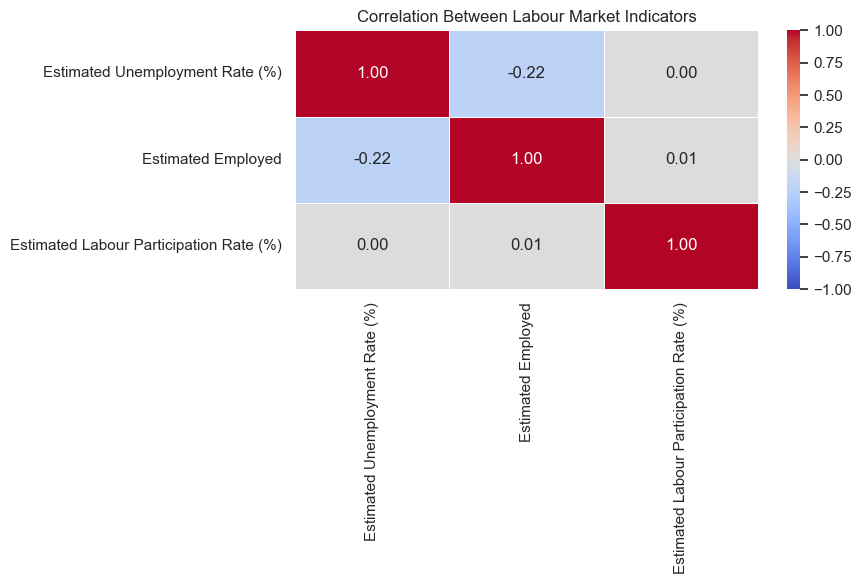

In [19]:
# Select the main labour market indicators
labour_indicators = df_india_clean[
    [
        "Estimated Unemployment Rate (%)",
        "Estimated Employed",
        "Estimated Labour Participation Rate (%)"
    ]
]

# Calculate the correlation matrix
correlation_matrix = labour_indicators.corr()

# Display correlation values
print("Correlation Matrix:")
display(correlation_matrix.round(2))

# Visualize the correlation matrix
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Labour Market Indicators")
plt.tight_layout()
plt.show()

### 6.7 Unemployment Trends Over Time

In this section, we examine how unemployment rates evolved over time.

We aggregate unemployment observations by month to identify general trends and significant changes during the period covered by the first dataset.

A line chart will be used to visualize the monthly average unemployment rate.

This analysis will provide an initial understanding of temporal variations before investigating the COVID-19 period in greater detail.

Monthly Average Unemployment Rate:


,Unemployment Rate (%)
Date,
2019-05-01,8.87
2019-06-01,9.30
2019-07-01,9.03
2019-08-01,9.64
2019-09-01,9.05
2019-10-01,9.90
2019-11-01,9.87
2019-12-01,9.50
2020-01-01,9.95


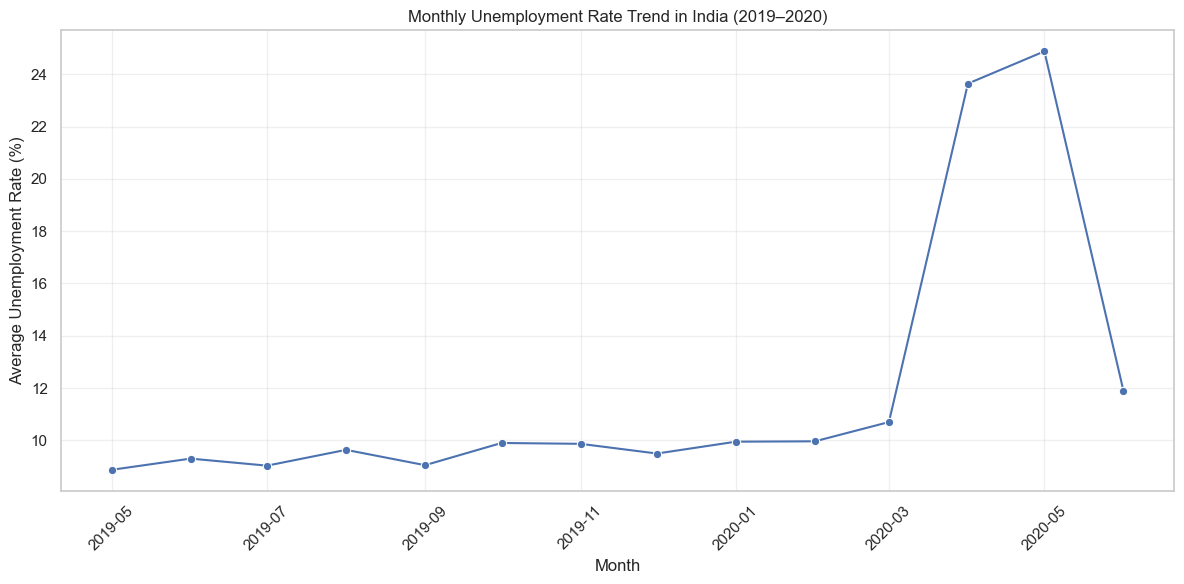

In [20]:
# Calculate the monthly average unemployment rate
monthly_unemployment = (
    df_india_clean
    .groupby(df_india_clean["Date"].dt.to_period("M"))[
        "Estimated Unemployment Rate (%)"
    ]
    .mean()
)

# Convert monthly periods into timestamps
monthly_unemployment.index = monthly_unemployment.index.to_timestamp()

# Display monthly results
print("Monthly Average Unemployment Rate:")
display(monthly_unemployment.round(2).to_frame("Unemployment Rate (%)"))

# Plot the monthly trend
plt.figure(figsize=(12, 6))

sns.lineplot(
    x=monthly_unemployment.index,
    y=monthly_unemployment.values,
    marker="o"
)

plt.title("Monthly Unemployment Rate Trend in India (2019–2020)")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Interpretation:**

The monthly analysis reveals a relatively stable unemployment rate between May 2019 and February 2020, generally ranging from 8.87% to 9.96%.

A significant increase occurred in March 2020, followed by a sharp rise in April (23.64%) and May (24.88%).

In June 2020, the average unemployment rate decreased to 11.90%.

This sudden increase coincides with the beginning of the COVID-19 pandemic and the lockdown period in India, suggesting a substantial disruption in the labour market.

Further analysis is required to investigate this relationship in greater detail.

### 6.8 Regional Unemployment Trends

In this section, we investigate how unemployment rates evolved across different regions over time.

The objective is to identify regional differences in monthly unemployment patterns and determine whether certain regions experienced more significant changes during the observed period.

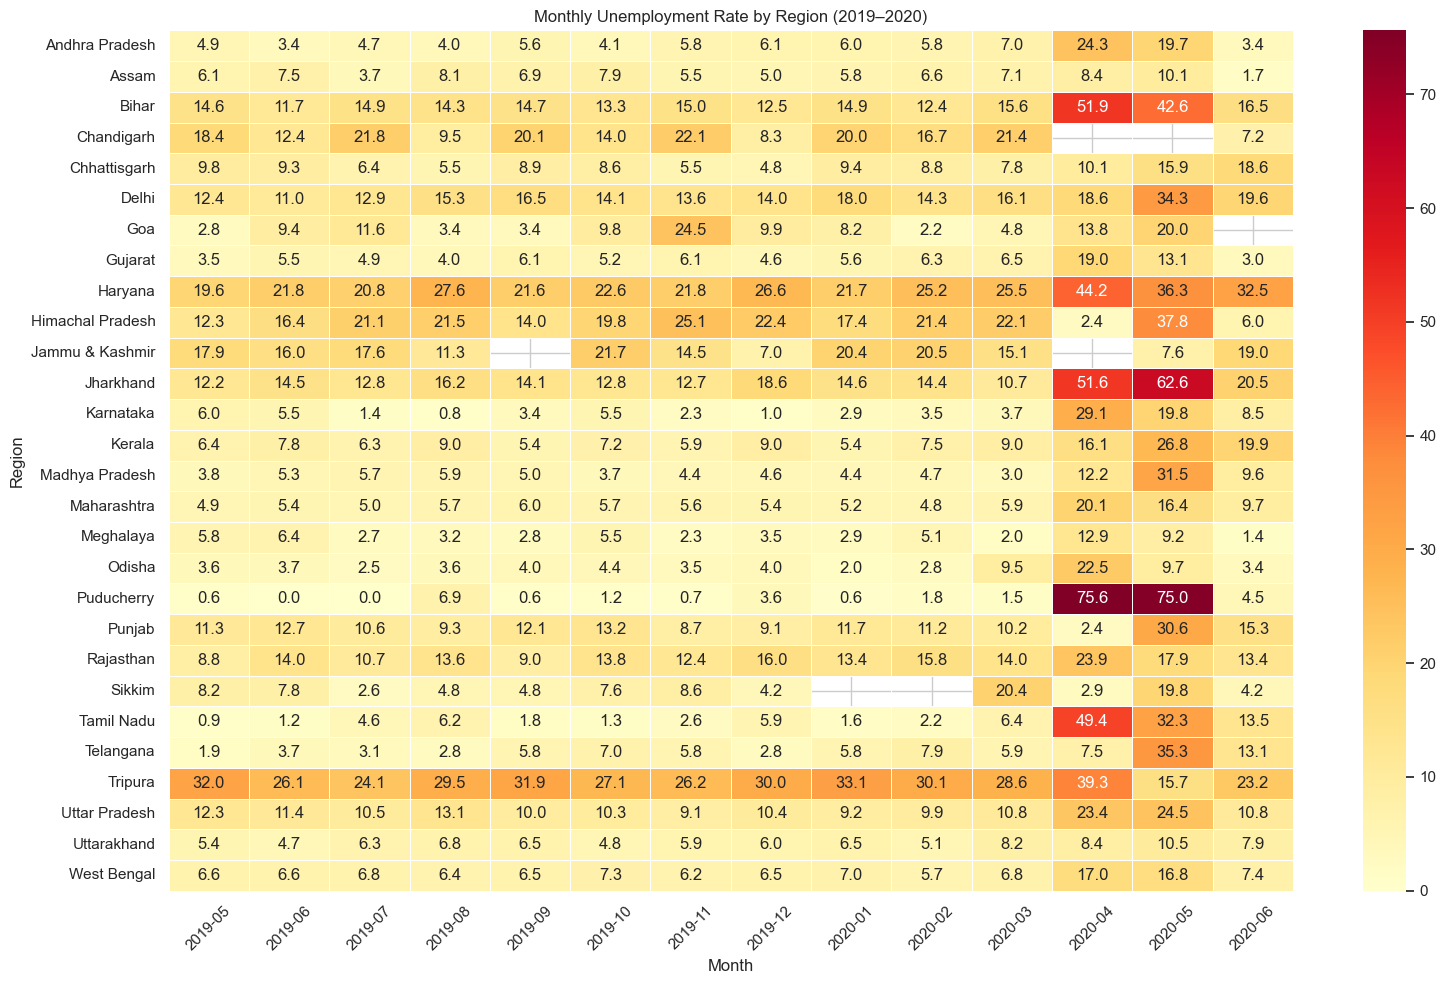

In [21]:
# Calculate average unemployment rate by region and month
regional_monthly = (
    df_india_clean
    .groupby([
        "Region",
        df_india_clean["Date"].dt.to_period("M")
    ])["Estimated Unemployment Rate (%)"]
    .mean()
    .reset_index()
)

# Rename the date column
regional_monthly.rename(columns={"Date": "Month"}, inplace=True)

# Convert monthly periods to strings
regional_monthly["Month"] = regional_monthly["Month"].astype(str)

# Create a pivot table
regional_pivot = regional_monthly.pivot(
    index="Region",
    columns="Month",
    values="Estimated Unemployment Rate (%)"
)

# Visualize regional unemployment trends
plt.figure(figsize=(16, 10))

sns.heatmap(
    regional_pivot,
    cmap="YlOrRd",
    annot=True,
    fmt=".1f",
    linewidths=0.5
)

plt.title("Monthly Unemployment Rate by Region (2019–2020)")
plt.xlabel("Month")
plt.ylabel("Region")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

**Interpretation:**

The regional heatmap reveals substantial differences in unemployment patterns across Indian regions.

Several regions experienced sharp increases in unemployment during April and May 2020.

Puducherry recorded particularly high unemployment rates, reaching 75.6% in April and 75.0% in May 2020. Jharkhand, Bihar, Tamil Nadu, and Haryana also experienced significant increases.

In June 2020, unemployment rates decreased in several regions.

These findings suggest that the labour market disruption during the COVID-19 period affected multiple regions, although the magnitude of the changes varied geographically.

Missing values in the heatmap represent unavailable regional observations and should not be interpreted as zero unemployment.

## 7. Key Findings

The exploratory data analysis revealed several important findings:

1. **Unemployment Distribution:** Both datasets show right-skewed unemployment rate distributions, with most observations concentrated below 15%.

2. **Regional Differences:** Significant differences exist across Indian regions. Tripura and Haryana recorded the highest average unemployment rates in Dataset 1, while Meghalaya recorded the lowest.

3. **Urban vs Rural Areas:** Urban areas showed a higher average unemployment rate (13.17%) than rural areas (10.32%).

4. **Extreme Values:** Several regions recorded unusually high unemployment rates during April and May 2020.

5. **Labour Market Correlations:** The correlation analysis showed weak linear relationships between unemployment, estimated employment, and labour participation.

6. **Temporal Trends:** Unemployment remained relatively stable until February 2020, followed by a sharp increase in April and May 2020.

7. **Regional COVID-19 Patterns:** The regional heatmap showed that several Indian regions experienced substantial increases during April and May 2020, followed by decreases in June 2020.

## 8. EDA Conclusion

The exploratory analysis provides an overview of unemployment patterns in India between May 2019 and October 2020 across the two datasets.

The findings highlight regional disparities, differences between rural and urban areas, and significant changes in unemployment rates during the COVID-19 period.

April and May 2020 stand out as particularly important months, with substantial increases observed across several regions.

These descriptive findings provide a foundation for a more detailed investigation of the potential impact of COVID-19 on unemployment.

The next stage will focus on temporal comparisons, regional variations, and the identification of possible seasonal patterns, where supported by the available data.

## 9. Exporting Cleaned Datasets

In this section, we export the cleaned datasets into CSV files.

These files will be reused in the second notebook to perform a more detailed analysis of the COVID-19 period and unemployment trends.

Exporting the cleaned data avoids repeating the preprocessing steps and ensures consistency between both notebooks.

In [22]:
# Export cleaned datasets
df_india_clean.to_csv(
    "../data/unemployment_india_cleaned.csv",
    index=False
)

df_upto_2020_clean.to_csv(
    "../data/unemployment_upto_2020_cleaned.csv",
    index=False
)

print("Cleaned datasets exported successfully!")

Cleaned datasets exported successfully!
